# Lab | Micromanage your agents

In [2]:
%pip install langsmith openai openevals python-dotenv pandas matplotlib -q

Note: you may need to restart the kernel to use updated packages.


#### Part 1 - Setpup & Documentation Selection

The dataset in qa_dataset.json is derived from the EU AI Act & GDPR course material. It contains 22 records.Each record contains `id`, `topic`, `difficulty`, `question`, `answer`, `source_file`, and `source_section`.


In [3]:
import os
from dotenv import load_dotenv

load_dotenv()

# turn tracing on, choose a descriptive project name, set your region
os.environ["LANGSMITH_TRACING"] = "true"
PROJECT_NAME ="lab-langsmith"
os.environ["LANGSMITH_PROJECT"] = PROJECT_NAME
os.environ["LANGSMITH_ENDPOINT"] = "https://eu.api.smith.langchain.com"    # US or EU endpoint

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from langsmith import Client, traceable
from langsmith.wrappers import wrap_openai
from openai import OpenAI
from openevals.llm import create_llm_as_judge
from openevals.prompts import CORRECTNESS_PROMPT
from getpass import getpass

OUT = Path("outputs"); OUT.mkdir(exist_ok=True)   # charts and CSVs are saved here


api_key = os.getenv("OPENAI_API_KEY")
if not api_key:
    api_key = getpass("OpenAI API key: ")
    os.environ["OPENAI_API_KEY"] = api_key

client = Client()

openai_client = wrap_openai(OpenAI())

### Part 2: Database creation
#### Step 3 - extract and structure the examples

In [5]:
import json

with open("qa_dataset.json", encoding="utf-8") as f:
    dataset = json.load(f)

examples = pd.DataFrame(dataset["examples"])

# Data quality checks
MIN_EXAMPLES = 10
assert len(examples) >= MIN_EXAMPLES, f"Expected at least {MIN_EXAMPLES} examples, found {len(examples)}"

required_keys = {"id", "topic", "difficulty", "question", "answer", "source_file", "source_section"}
example_key_sets = [set(example) for example in dataset["examples"]]
assert all(keys == required_keys for keys in example_key_sets), "Examples do not all have the same keys"
assert set(examples.columns) == required_keys, "Dataset schema does not match the required keys"

for field in ("question", "answer"):
    empty_rows = examples[field].isna() | examples[field].astype(str).str.strip().eq("")
    assert not empty_rows.any(), f"Empty {field} in rows: {examples.index[empty_rows].tolist()}"

print(f"Validated {len(examples)} examples.")
print("\nExamples per category:")
display(examples["topic"].value_counts().rename_axis("category").to_frame("count"))
print("Examples per difficulty:")
display(examples["difficulty"].value_counts().rename_axis("difficulty").to_frame("count"))

Validated 22 examples.

Examples per category:


,count
category,
GDPR,12
EU AI Act,10


Examples per difficulty:


,count
difficulty,
intermediate,10
advanced,7
foundational,5


#### Step 4 - Create the LangSmith dataset

In [6]:
DATASET_NAME = "eu-ai-act-gdpr-qa-v1"
DATASET_DESCRIPTION = (
    "Grounded Q&A evaluation examples covering EU AI Act and GDPR compliance, "
    "including topic, difficulty, and source metadata."
)
dataset_records = dataset["examples"]

# Reuse the dataset when it already exists so rerunning this cell does not duplicate examples.
existing_dataset = next(client.list_datasets(dataset_name=DATASET_NAME), None)
if existing_dataset is None:
    langsmith_dataset = client.create_dataset(
        dataset_name=DATASET_NAME,
        description=DATASET_DESCRIPTION,
    )

    inputs = [{"question": row["question"]} for row in dataset_records]
    outputs = [{"answer": row["answer"]} for row in dataset_records]
    metadata = [
        {
            "category": row["topic"],
            "difficulty": row["difficulty"],
            "source_file": row["source_file"],
            "source_section": row["source_section"],
            "record_id": row["id"],
        }
        for row in dataset_records
    ]

    client.create_examples(
        inputs=inputs,
        outputs=outputs,
        metadata=metadata,
        dataset_id=langsmith_dataset.id,
    )
    print(f"Created '{DATASET_NAME}' and uploaded {len(inputs)} examples.")
else:
    langsmith_dataset = existing_dataset
    print(f"'{DATASET_NAME}' already exists; skipping upload.")

stored_examples = list(client.list_examples(dataset_name=DATASET_NAME))
stored_count = len(stored_examples)
assert stored_count == len(dataset_records), (
    f"Expected {len(dataset_records)} examples in LangSmith, found {stored_count}"
)
print(f"Verified '{DATASET_NAME}' contains {stored_count} examples.")

'eu-ai-act-gdpr-qa-v1' already exists; skipping upload.
Verified 'eu-ai-act-gdpr-qa-v1' contains 22 examples.


### Part 3 - Evaluation Setup
#### Step 5: Target function

In [7]:
MODEL = os.getenv("OPENAI_MODEL", "gpt-4o-mini")

SYSTEM_PROMPT = """
Answer questions about the EU AI Act and GDPR using the provided course
material. Be accurate, concise, and practical. Do not invent facts. If the
material does not contain enough information, say that clearly. This is
educational content and not legal advice.
"""

@traceable(name="lab-target")
def target(inputs: dict) -> dict:
    """Generate an answer for one LangSmith evaluation example."""
    try:
        question = inputs["question"]
        context = inputs.get("context", "")
        user_message = f"Context:\n{context}\n\nQuestion:\n{question}" if context else question
        response = openai_client.chat.completions.create(
            model=MODEL,
            temperature=0,
            max_tokens=500,
            messages=[
                {"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user", "content": user_message},
            ],
        )
        answer = response.choices[0].message.content or ""
        return {"answer": answer.strip()}
    except Exception as e:
        return {"answer": "", "error": str(e)}

# Smoke-test the target on two examples.
target_test_results = [
    target({"question": row["question"]})
    for _, row in examples.head(2).iterrows()
]
for index, result in enumerate(target_test_results, start=1):
    print(f"Test example {index}: {result}")

Test example 1: {'answer': 'The four AI Act outcome categories that should be represented in the consulting exercise are:\n\n1. **Unacceptable Risk**: AI systems that pose a clear threat to safety, livelihoods, and rights, which are prohibited.\n2. **High Risk**: AI systems that require strict compliance with regulations due to their potential impact on fundamental rights and safety.\n3. **Limited Risk**: AI systems that have specific transparency obligations but are not subject to the same level of scrutiny as high-risk systems.\n4. **Minimal Risk**: AI systems that pose little or no risk and are largely unregulated.\n\nThese categories help in assessing the risk level associated with different AI applications and determining the appropriate regulatory framework.'}
Test example 2: {'answer': 'The course material does not provide specific details about what facts should be included in a hidden client brief. Therefore, I cannot provide a definitive answer. For accurate information, plea

#### Step 6: Evaluators

In [8]:
_judge = create_llm_as_judge(
    prompt=CORRECTNESS_PROMPT,
    model="openai:gpt-5.4-mini",
    feedback_key="correctness",
)

def correctness_evaluator(inputs: dict, outputs: dict, reference_outputs: dict) -> dict:
    return _judge(inputs=inputs, outputs=outputs, reference_outputs=reference_outputs)
    

# Evaluator 2: deterministic token-overlap score (no LLM or API call).
import re

def _answer_tokens(value) -> set[str]:
    return set(re.findall(r"\b[a-z0-9]+\b", str(value or "").lower()))

def rule_evaluator(
    inputs: dict,
    outputs: dict,
    reference_outputs: dict,
) -> dict:
    """Score generated answers by F1 overlap with the reference answer."""
    predicted = _answer_tokens(outputs.get("answer", ""))
    reference = _answer_tokens(reference_outputs.get("answer", ""))

    if not predicted or not reference:
        return {
            "key": "reference_token_f1",
            "score": 0.0,
            "comment": "Generated or reference answer is empty.",
        }

    overlap = predicted & reference
    precision = len(overlap) / len(predicted)
    recall = len(overlap) / len(reference)
    score = 2 * precision * recall / (precision + recall) if precision + recall else 0.0

    return {
        "key": "reference_token_f1",
        "score": round(score, 3),
        "comment": (
            f"Matched {len(overlap)} of {len(reference)} reference terms; "
            f"precision={precision:.3f}, recall={recall:.3f}."
        ),
    }

# Local, deterministic smoke test (does not call an LLM).
print(rule_evaluator(
    inputs={"question": "example"},
    outputs={"answer": "High-risk AI requires human oversight."},
    reference_outputs={"answer": "High-risk AI systems require human oversight and documentation."},
))

{'key': 'reference_token_f1', 'score': 0.667, 'comment': 'Matched 5 of 9 reference terms; precision=0.833, recall=0.556.'}


In [9]:
# Test the deterministic evaluator on one correct and one deliberately wrong answer.
test_inputs = {"question": "What controls are required for high-risk AI?"}
test_reference = {"answer": "High-risk AI requires human oversight and documentation."}
correct_result = rule_evaluator(
    inputs=test_inputs,
    outputs={"answer": "High-risk AI requires human oversight and documentation."},
    reference_outputs=test_reference,
)
wrong_result = rule_evaluator(
    inputs=test_inputs,
    outputs={"answer": "This concerns cafeteria menu planning."},
    reference_outputs=test_reference,
)
print("Correct answer:", correct_result)
print("Wrong answer:", wrong_result)
assert correct_result["score"] > wrong_result["score"]

Correct answer: {'key': 'reference_token_f1', 'score': 1.0, 'comment': 'Matched 8 of 8 reference terms; precision=1.000, recall=1.000.'}
Wrong answer: {'key': 'reference_token_f1', 'score': 0.0, 'comment': 'Matched 0 of 8 reference terms; precision=0.000, recall=0.000.'}


### Part 4: Run the evaluation

#### Step 7: Execute the experiment

In [12]:
EXPERIMENT_PREFIX = f"{MODEL}-promptv1-llmcorrectness-tokenf1"

# Run both evaluators: LLM correctness plus deterministic token-overlap F1.
evaluation_results = client.evaluate(
    target,
    data=DATASET_NAME,
    evaluators=[correctness_evaluator, rule_evaluator],
    experiment_prefix=EXPERIMENT_PREFIX,
    description="EU AI Act and GDPR Q&A evaluation using deterministic token-overlap F1.",
    metadata={"evaluator": "reference_token_f1", "model": MODEL},
    max_concurrency=2,
    error_handling="log",
    blocking=True,
)
print(f"Evaluation completed: {EXPERIMENT_PREFIX}")

View the evaluation results for experiment: 'gpt-4o-mini-promptv1-llmcorrectness-tokenf1-24f6f2fd' at:
https://eu.smith.langchain.com/o/838757a7-69cb-4e13-91ff-ef778440e79f/datasets/151b065f-25bb-4c1d-b1d7-9d0cb12d84b3/compare?selectedSessions=4ffe12c2-e568-45e4-89a5-6463faf9cc62




0it [00:00, ?it/s]

Evaluation completed: gpt-4o-mini-promptv1-llmcorrectness-tokenf1


In [13]:
# Collect the experiment results and verify that every dataset example was processed.
results_df = evaluation_results.to_pandas()
processed_count = len(results_df)
expected_count = len(dataset_records)
assert processed_count == expected_count, (
    f"Expected {expected_count} processed examples, found {processed_count}"
)
print(f"Processed {processed_count}/{expected_count} examples.")
print("Result columns:", results_df.columns.tolist())
results_df.to_csv(OUT / "results_main.csv", index=False)
print(f"Saved results to {OUT / 'results_main.csv'}")

Processed 22/22 examples.
Result columns: ['inputs.question', 'outputs.answer', 'error', 'reference.answer', 'feedback.correctness', 'feedback.reference_token_f1', 'execution_time', 'example_id', 'id']
Saved results to outputs/results_main.csv


#### Step 8: Review the results in the LangSmith UI


**Go and look:** click the experiment link printed above.
- Open 2–3 **failed** examples and read the judge's reasoning (`comment`).
- Do the LLM judge and your rule-based evaluator **agree**? Look at the rows where they don't.
- Take **screenshots** (experiment table + one trace) for your repo.

** First observations + experiment link:**

link and observations are in /outputs
https://eu.smith.langchain.com/o/838757a7-69cb-4e13-91ff-ef778440e79f/datasets/151b065f-25bb-4c1d-b1d7-9d0cb12d84b3/compare?selectedSessions=4ffe12c2-e568-45e4-89a5-6463faf9cc62&scroll_to=feedback

### Part 5: Analysis & Reporting

#### Step 9: Analysis Results

In [14]:
# Aggregate metrics for every evaluator returned by LangSmith.
df = results_df.copy()
feedback_columns = [column for column in df.columns if column.startswith("feedback.")]
metric_rows = []
for column in feedback_columns:
    scores = pd.to_numeric(df[column], errors="coerce")
    metric_rows.append({
        "evaluator": column.removeprefix("feedback."),
        "n": scores.notna().sum(),
        "mean_score": scores.mean(),
        "median_score": scores.median(),
        "failed_below_0_5": (scores < 0.5).sum(),
        "pass_rate": (scores >= 0.5).mean(),
    })
metrics_df = pd.DataFrame(metric_rows)
display(metrics_df)
metrics_df.to_csv(OUT / "evaluation_metrics.csv", index=False)

,evaluator,n,mean_score,median_score,failed_below_0_5,pass_rate
0,correctness,22,0.272727,0.000,16,0.272727
1,reference_token_f1,22,0.202773,0.207,22,0.000000


Mean score by category:


,feedback.correctness,feedback.reference_token_f1
category,,
EU AI Act,0.30,0.197
GDPR,0.25,0.208


Mean score by difficulty:


,feedback.correctness,feedback.reference_token_f1
difficulty,,
advanced,0.286,0.198
foundational,0.400,0.245
intermediate,0.200,0.185


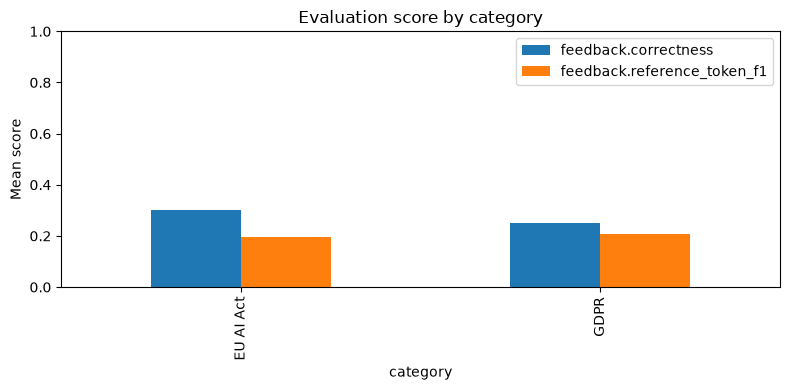

In [15]:
# Join LangSmith results with example metadata, then compare topic and difficulty.
meta = pd.DataFrame([
    {"example_id": str(e.id), **(e.metadata or {})}
    for e in client.list_examples(dataset_name=DATASET_NAME)
])
df["example_id"] = df["example_id"].astype(str)
df = df.merge(meta, on="example_id", how="left")

score_columns = [column for column in df.columns if column.startswith("feedback.")]
for column in score_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

group_columns = [column for column in ("category", "difficulty") if column in df.columns]
grouped_tables = {}
for group_column in group_columns:
    grouped = df.groupby(group_column)[score_columns].mean().round(3)
    grouped_tables[group_column] = grouped
    print(f"Mean score by {group_column}:")
    display(grouped)

if score_columns and "category" in df.columns:
    df.groupby("category")[score_columns].mean().plot(kind="bar", figsize=(8, 4), ylim=(0, 1))
    plt.ylabel("Mean score")
    plt.title("Evaluation score by category")
    plt.tight_layout()
    plt.savefig(OUT / "pass_rate_by_category.png", dpi=150)
    plt.show()

df.to_csv(OUT / "evaluation_results_with_metadata.csv", index=False)

In [16]:
# Error analysis: retain every example with a failing evaluator score.
failed_masks = [(df[column] < 0.5) for column in score_columns]
failed_df = df[pd.concat(failed_masks, axis=1).any(axis=1)] if failed_masks else df.iloc[0:0]
error_columns = [column for column in ("inputs.question", "outputs.answer", "reference.answer", "error") if column in failed_df.columns]
error_analysis = failed_df[error_columns + [column for column in score_columns if column in failed_df.columns]].copy()
error_analysis["failure_type"] = error_analysis.apply(
    lambda row: "api_error" if "error" in row and pd.notna(row["error"]) else "needs_manual_review",
    axis=1,
)
display(error_analysis)
error_analysis.to_csv(OUT / "error_analysis.csv", index=False)
print(f"Identified {len(error_analysis)} failed examples for manual review.")

,inputs.question,outputs.answer,reference.answer,error,feedback.correctness,feedback.reference_token_f1,failure_type
0,What facts should every hidden client brief co...,The course material does not provide specific ...,"It should identify the company or industry, bu...",None,False,0.123,needs_manual_review
1,What should the CV-screening product do with s...,The CV-screening product should ensure that it...,It should minimise inputs and be designed not ...,None,False,0.119,needs_manual_review
2,What is the likely controller/processor model ...,The likely controller/processor model for a CV...,Each employer customer is the controller and d...,None,False,0.229,needs_manual_review
3,What separate purposes should be distinguished...,The course material does not provide specific ...,The map should separate operational shift or s...,None,False,0.317,needs_manual_review
4,What roles must be mapped in the proposed AI a...,The proposed AI architecture under the EU AI A...,"The architecture should identify the provider,...",None,False,0.156,needs_manual_review
5,When might warehouse attendance or productivit...,Warehouse attendance or productivity data may ...,The stated data is not automatically Article 9...,None,True,0.205,needs_manual_review
6,What is the required decision rule for a prohi...,The course material does not provide specific ...,Deny the use as proposed and offer a redesigne...,None,False,0.160,needs_manual_review
7,What must be done before relying on legitimate...,Before relying on legitimate interests for wor...,"The controller must define the purpose, assess...",None,True,0.246,needs_manual_review
8,Why is a warehouse workforce-planning tool pro...,The warehouse workforce-planning tool is provi...,It allocates shifts and stations using individ...,None,False,0.141,needs_manual_review
9,What is the recommended launch decision for th...,The provided course material does not contain ...,Go with conditions. Before live applicant proc...,None,False,0.067,needs_manual_review


Identified 22 failed examples for manual review.


The metrics, grouped analysis, and failed examples above provide the quantitative and qualitative findings for the report. Scores are estimates for this 22-example dataset; disagreements between the LLM judge and deterministic evaluator require manual review.

In [17]:
deterministic_column = next((c for c in score_columns if "reference_token_f1" in c), None)
mean_score = df[deterministic_column].mean() if deterministic_column else float("nan")
pass_rate = (df[deterministic_column] >= 0.5).mean() if deterministic_column else float("nan")
report = f"""# Evaluation summary

We evaluated {len(df)} EU AI Act and GDPR Q&A examples with {MODEL} using the traced target function. Step 7 ran both the LLM correctness evaluator and the deterministic reference-token F1 evaluator; the deterministic evaluator's mean score was {mean_score:.3f} with a {pass_rate:.1%} pass rate at the 0.5 threshold. Results were compared by category and difficulty, and failed examples were exported for manual review. Token overlap is reproducible and inexpensive but can penalize valid paraphrases, while the LLM judge is model-dependent; neither metric replaces expert legal review. The recommended next step is to inspect evaluator disagreements and add paraphrase-aware and expert-reviewed cases.
"""
(OUT.parent / "evaluation_summary.md").write_text(report, encoding="utf-8")
print(report)
print("Saved evaluation_summary.md and analysis artifacts in outputs/.")

# Evaluation summary

We evaluated 22 EU AI Act and GDPR Q&A examples with gpt-4o-mini using the traced target function. Step 7 ran both the LLM correctness evaluator and the deterministic reference-token F1 evaluator; the deterministic evaluator's mean score was 0.203 with a 0.0% pass rate at the 0.5 threshold. Results were compared by category and difficulty, and failed examples were exported for manual review. Token overlap is reproducible and inexpensive but can penalize valid paraphrases, while the LLM judge is model-dependent; neither metric replaces expert legal review. The recommended next step is to inspect evaluator disagreements and add paraphrase-aware and expert-reviewed cases.

Saved evaluation_summary.md and analysis artifacts in outputs/.


#### Step 10: `evaluation_summary.md`

In [18]:
# Build the required concise Step 10 report at the repository root.
metric_lines = [
    f"| {row.evaluator} | {row.mean_score:.3f} | {row.pass_rate:.1%} | {int(row.n)} |"
    for row in metrics_df.itertuples()
]
metric_table = "\n".join(metric_lines) or "| No scores available | — | — | 0 |"
failure_count = len(error_analysis)
summary = f"""# Evaluation summary

We evaluated {len(df)} grounded EU AI Act and GDPR Q&A examples across the EU AI Act and GDPR categories with {MODEL} at temperature 0. The experiment used the LLM correctness evaluator and the deterministic reference-token F1 evaluator; {failure_count} examples were flagged for review. The deterministic metric is reproducible and inexpensive, but token overlap can penalize valid paraphrases, while the LLM judge is model-dependent and neither metric replaces expert legal review. The biggest failure pattern should be confirmed by reviewing `outputs/error_analysis.csv`; the recommended next step is to inspect evaluator disagreements and add paraphrase-aware, expert-reviewed cases.

| Metric | Mean score | Pass rate (>= 0.5) | N |
|---|---:|---:|---:|
{metric_table}

Experiment prefix: `{EXPERIMENT_PREFIX}`
"""
Path("evaluation_summary.md").write_text(summary, encoding="utf-8")
print(summary)
print("Saved evaluation_summary.md at the repository root.")

# Evaluation summary

We evaluated 22 grounded EU AI Act and GDPR Q&A examples across the EU AI Act and GDPR categories with gpt-4o-mini at temperature 0. The experiment used the LLM correctness evaluator and the deterministic reference-token F1 evaluator; 22 examples were flagged for review. The deterministic metric is reproducible and inexpensive, but token overlap can penalize valid paraphrases, while the LLM judge is model-dependent and neither metric replaces expert legal review. The biggest failure pattern should be confirmed by reviewing `outputs/error_analysis.csv`; the recommended next step is to inspect evaluator disagreements and add paraphrase-aware, expert-reviewed cases.

| Metric | Mean score | Pass rate (>= 0.5) | N |
|---|---:|---:|---:|
| correctness | 0.273 | 27.3% | 22 |
| reference_token_f1 | 0.203 | 0.0% | 22 |

Experiment prefix: `gpt-4o-mini-promptv1-llmcorrectness-tokenf1`

Saved evaluation_summary.md at the repository root.


### Part 6: Custom Evaluation

#### A/B Comparison

In [22]:
def target_gpt54_mini(inputs: dict) -> dict:
    # Note: do NOT list "A, B, C, or D" in the prompt; some HLE questions have up to 10 options (A-J).
    response = openai_client.chat.completions.create(
        model="gpt-5.4-mini",
        messages=[
            {"role": "system", "content": "You are answering a multiple-choice exam question. Reply with only the letter of the correct answer."},
            {"role": "user",   "content": inputs["question"]},
        ],
        # GPT-5 family: 'max_tokens' is NOT supported -> use 'max_completion_tokens'.
        # reasoning_effort="none" -> answer directly; hidden reasoning tokens would otherwise
        # eat the 10-token budget and return an empty answer.
        max_completion_tokens=10,
        reasoning_effort="none",
    )
    return {"answer": response.choices[0].message.content.strip()}

results_54mini = client.evaluate(
    target_gpt54_mini,
    data=DATASET_NAME,
    evaluators=[correctness_evaluator, rule_evaluator],
    experiment_prefix="gpt-5.4-mini",
    max_concurrency=2,
)
print(results_54mini)

View the evaluation results for experiment: 'gpt-5.4-mini-77574355' at:
https://eu.smith.langchain.com/o/838757a7-69cb-4e13-91ff-ef778440e79f/datasets/151b065f-25bb-4c1d-b1d7-9d0cb12d84b3/compare?selectedSessions=42f0d604-226d-443d-a208-f086acef966d




0it [00:00, ?it/s]

<ExperimentResults gpt-5.4-mini-77574355>


In [23]:
import pandas as pd

results_mini = evaluation_results

def summarize(results, model_name):
    df = results.to_pandas()   # one row per example; scores are in "feedback.<key>" columns
    row = {"model": model_name, "n_examples": len(df)}
    for key in ["correctness", "reference_token_f1"]:
        column = f"feedback.{key}"
        if column not in df.columns:
            row[f"{key}_mean"] = float("nan")
            row[f"{key}_n"] = 0
            continue
        s = pd.to_numeric(df[column], errors="coerce").dropna()
        row[f"{key}_mean"] = round(s.mean(), 3)
        row[f"{key}_n"] = len(s)
    return row

summary = pd.DataFrame([
    summarize(results_mini,   "gpt-4o-mini"),
    summarize(results_54mini, "gpt-5.4-mini"),
])
display(summary)
summary.to_csv(OUT / "model_comparison_summary.csv", index=False)
print("With only 22 questions, small score differences should be treated as estimates.")

,model,n_examples,correctness_mean,correctness_n,reference_token_f1_mean,reference_token_f1_n
0,gpt-4o-mini,22,0.273,22,0.203,22
1,gpt-5.4-mini,22,0.000,22,0.005,22


With only 22 questions, small score differences should be treated as estimates.
